# 01 - Dataset Exploration & Resolution Verification

**Objective:** Explore the raw corn kernel image dataset (`data/raw/sehat` and `data/raw/terkontaminasi`), verify image counts, check resolution consistency (`224x224`), and inspect background/lighting regimes (dark fabric, light/white background, and pure black background).

In [1]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = "../data/raw"
CLASSES = ["sehat", "terkontaminasi"]
CLASS_LABELS = {"sehat": "Healthy", "terkontaminasi": "Contaminated"}

records = []
for cls in CLASSES:
    folder = os.path.join(RAW_DIR, cls)
    files = sorted(glob.glob(os.path.join(folder, "*")))
    for fpath in files:
        img = cv2.imread(fpath)
        if img is None:
            continue
        h, w, c = img.shape
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        border = np.concatenate([gray[:8, :].ravel(), gray[-8:, :].ravel(), gray[:, :8].ravel(), gray[:, -8:].ravel()])
        bg_med = float(np.median(border))
        bg_type = "Light/White BG" if bg_med > 75 else ("Dark Fabric BG" if bg_med > 10 else "Pure Black BG")
        records.append({
            "filename": os.path.basename(fpath),
            "label": cls,
            "width": w,
            "height": h,
            "channels": c,
            "mean_intensity": round(float(gray.mean()), 2),
            "border_median": round(bg_med, 1),
            "bg_regime": bg_type
        })

df_raw = pd.DataFrame(records)
print(f"Total Raw Images: {len(df_raw)}")
print("\nClass Distribution:")
print(df_raw["label"].value_counts())
print("\nResolution Summary:")
print(df_raw.groupby(["label", "width", "height"]).size())
print("\nBackground Regime Distribution:")
print(pd.crosstab(df_raw["label"], df_raw["bg_regime"]))

Total Raw Images: 1016

Class Distribution:
label
sehat             509
terkontaminasi    507
Name: count, dtype: int64

Resolution Summary:
label           width  height
sehat           224    224       508
                       229         1
terkontaminasi  224    223         1
                       224       499
                       258         1
                244    244         6
dtype: int64

Background Regime Distribution:
bg_regime       Dark Fabric BG  Light/White BG  Pure Black BG
label                                                        
sehat                      232             143            134
terkontaminasi             165             180            162


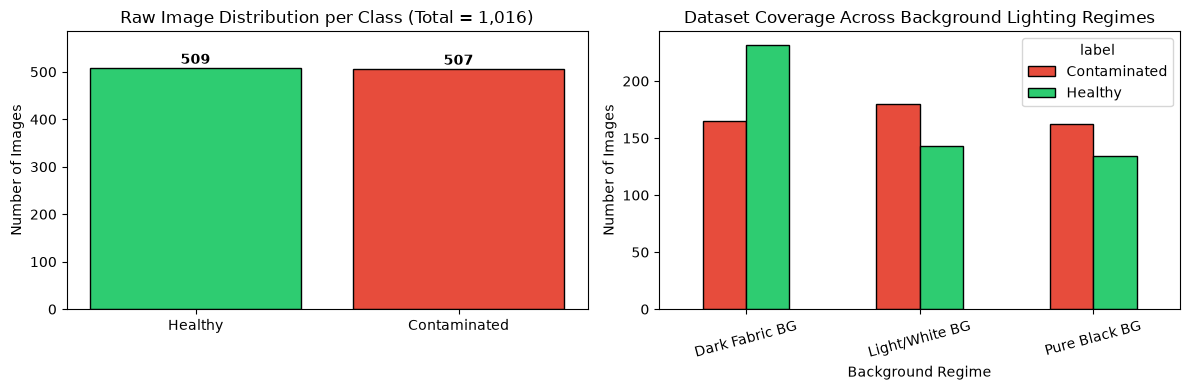

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df_raw["label"].map(CLASS_LABELS).value_counts()
axes[0].bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c"], edgecolor="black")
axes[0].set_title("Raw Image Distribution per Class (Total = 1,016)")
axes[0].set_ylabel("Number of Images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, str(v), ha="center", fontweight="bold")
axes[0].set_ylim(0, max(counts.values) * 1.15)

ct = pd.crosstab(df_raw["bg_regime"], df_raw["label"].map(CLASS_LABELS))
ct.plot(kind="bar", ax=axes[1], color=["#e74c3c", "#2ecc71"], edgecolor="black", rot=15)
axes[1].set_title("Dataset Coverage Across Background Lighting Regimes")
axes[1].set_ylabel("Number of Images")
axes[1].set_xlabel("Background Regime")

plt.tight_layout()
plt.show()

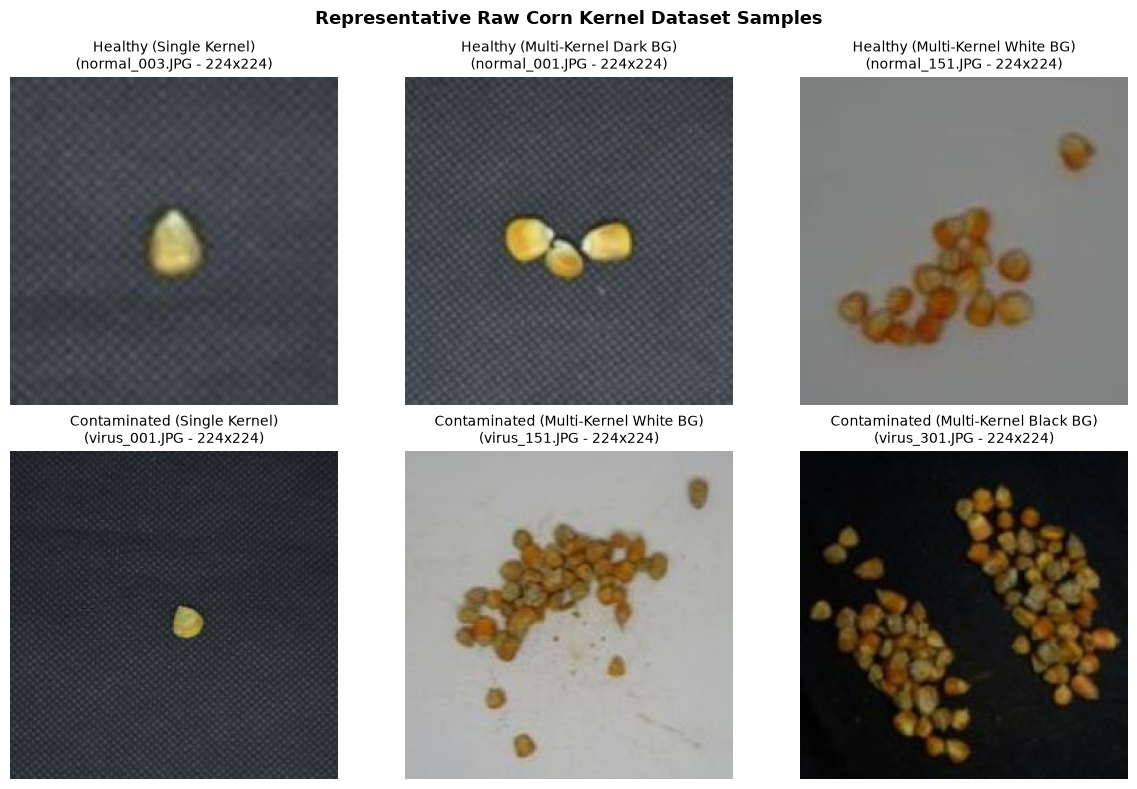

In [3]:
# Visualize sample images across single-kernel, multi-kernel, dark-BG, and white-BG regimes
sample_files = [
    ("sehat", "normal_003.JPG", "Healthy (Single Kernel)"),
    ("sehat", "normal_001.JPG", "Healthy (Multi-Kernel Dark BG)"),
    ("sehat", "normal_151.JPG", "Healthy (Multi-Kernel White BG)"),
    ("terkontaminasi", "virus_001.JPG", "Contaminated (Single Kernel)"),
    ("terkontaminasi", "virus_151.JPG", "Contaminated (Multi-Kernel White BG)"),
    ("terkontaminasi", "virus_301.JPG", "Contaminated (Multi-Kernel Black BG)")
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (cls, fname, title) in zip(axes.flat, sample_files):
    img = cv2.imread(os.path.join(RAW_DIR, cls, fname))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{title}\n({fname} - {img.shape[1]}x{img.shape[0]})", fontsize=10)
    ax.axis("off")

plt.suptitle("Representative Raw Corn Kernel Dataset Samples", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()